# 04 — Printed surfaces and the stacking-rate curve

The answer to "what fraction of releases stack, at each offset?" for S40, with smooth CAD surfaces, as printed
(0.2 mm layers) and with the cone sanded. Each offset gets N releases with friction, release height, tilt and
sideways speed drawn from the constraints (DD-STACK SP-9). Then the curve is combined with the arm's
placement error to give the overall king-stacking rate (SP-10).

In [1]:
# Setup: works from this folder whether or not the package was pip-installed
import sys, os, json
HERE = os.path.abspath("")
ROOT = os.path.dirname(HERE) if os.path.basename(HERE) == "notebooks" else HERE
if ROOT not in sys.path:
    sys.path.insert(0, ROOT)
import numpy as np
import matplotlib.pyplot as plt
import stackpieces
print("stackpieces", stackpieces.__version__, "| folder", os.path.relpath(ROOT))
CONSTRAINTS = os.path.join(ROOT, "constraints", "checkers_rot3u.json")
REFERENCE = os.path.join(ROOT, "results", "reference", "results.json")
c = json.load(open(CONSTRAINTS))
QUICK = True   # True: a few minutes, coarse. False: the full reference run (tens of minutes).

stackpieces 0.1.0 | folder ..


In [2]:
from stackpieces.geometry import make_piece, PRESETS
from stackpieces.montecarlo import stacking_curve, crossing, reliable_offset, rates
g = make_piece(PRESETS["S40"])
n = 8 if QUICK else None                       # None: releases_per_offset from the constraints
offs = [x * 1.0 for x in range(13)] if QUICK else None
curves = {}
for v in ("smooth", "layered", "hybrid"):
    curves[v] = stacking_curve(g, c, v, n=n, offsets=offs)
    print(f"{v:8s} 50 % at {crossing(curves[v])} mm, reliable (>= {c['goal']['seat_rate_required']:.0%}) to "
          f"{reliable_offset(curves[v], c['goal']['seat_rate_required'])} mm, {curves[v]['meta']['seconds']} s")

smooth   50 % at 5.333333333333333 mm, reliable (>= 80%) to 4.0 mm, 1.5 s


layered  50 % at 3.75 mm, reliable (>= 80%) to 1.0 mm, 13.2 s


hybrid   50 % at 3.6 mm, reliable (>= 80%) to 3.0 mm, 8.1 s


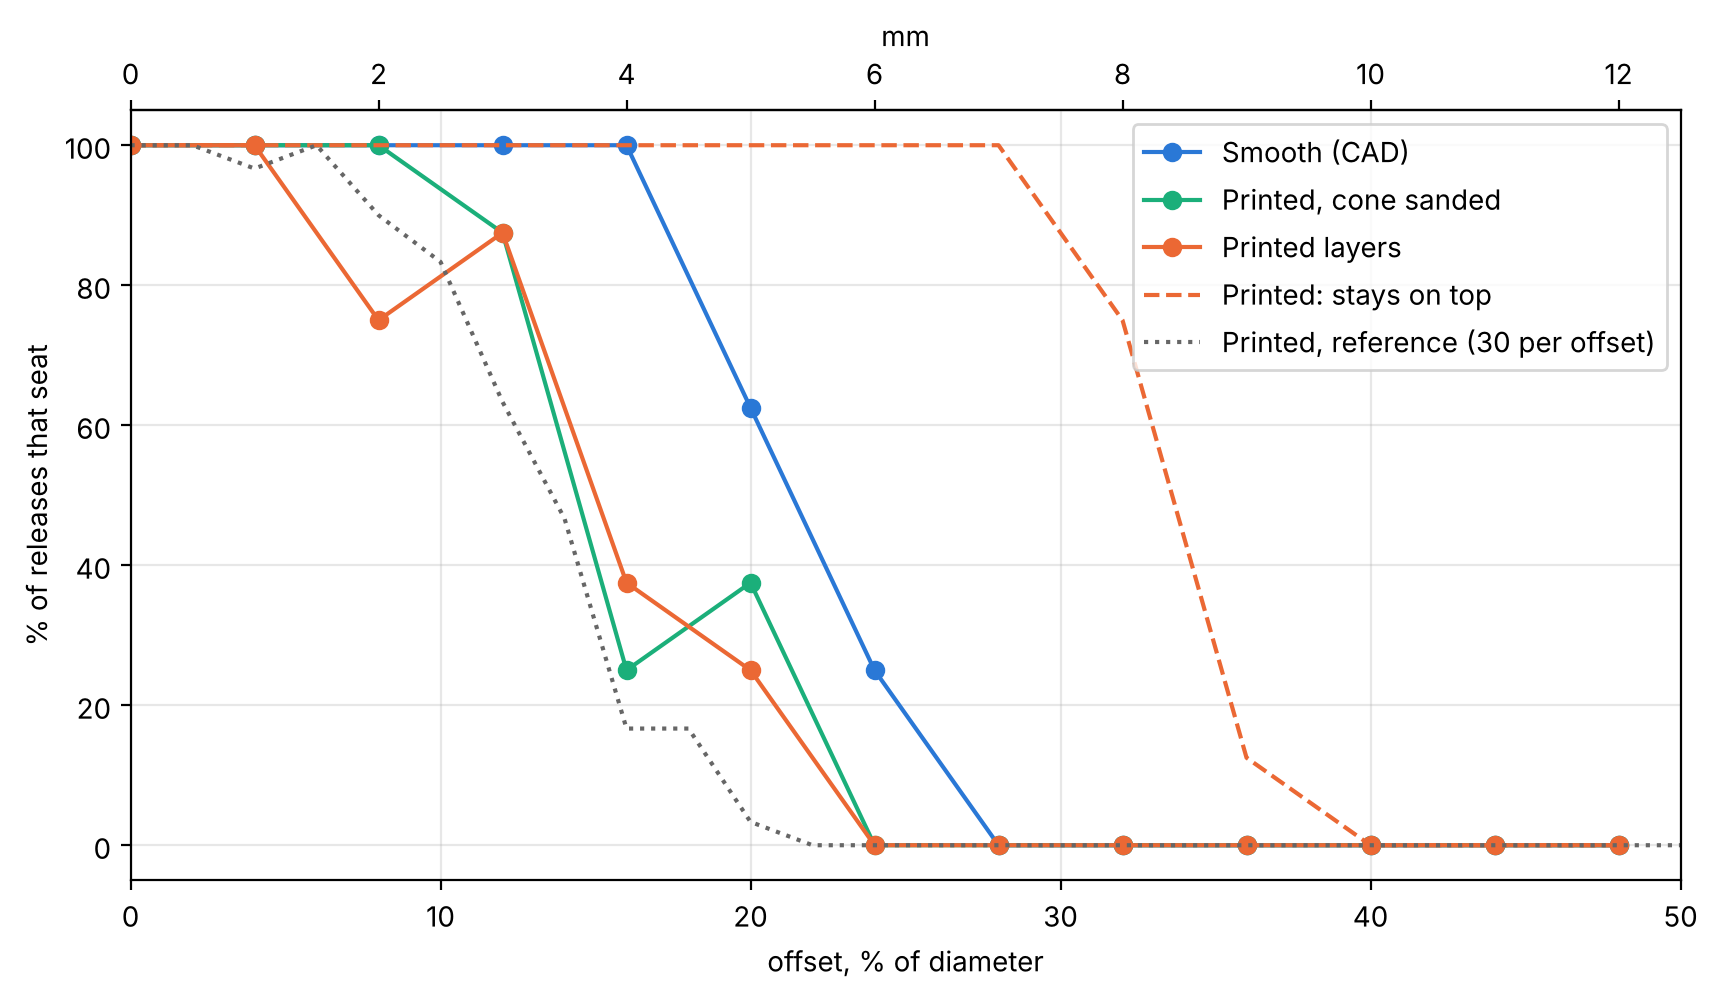

In [3]:
D = c["piece"]["diameter_mm"]
fig, ax = plt.subplots(figsize=(10, 5))
for v, col, name in (("smooth", "#2a78d6", "Smooth (CAD)"), ("hybrid", "#1baf7a", "Printed, cone sanded"), ("layered", "#eb6834", "Printed layers")):
    e, f = rates(curves[v]); ax.plot(100 * e / D, 100 * f, "o-", c=col, label=name)
e, f = rates(curves["layered"], ("seated", "perched")); ax.plot(100 * e / D, 100 * f, "--", c="#eb6834", label="Printed: stays on top")
if os.path.exists(REFERENCE):
    ref = json.load(open(REFERENCE))["curves"]["S40"]["layered"]
    er = np.array([r["e"] for r in ref["rows"]]); fr = np.array([r["counts"]["seated"] for r in ref["rows"]]) / ref["n"]
    ax.plot(100 * er / D, 100 * fr, ":", c="0.4", label=f"Printed, reference ({ref['n']} per offset)")
ax.set_xlabel("offset, % of diameter"); ax.set_ylabel("% of releases that seat"); ax.set_xlim(0, 50); ax.legend(); ax.grid(alpha=.3)
sec = ax.secondary_xaxis("top", functions=(lambda p: p * D / 100, lambda mm: mm * 100 / D)); sec.set_xlabel("mm")
plt.show()

## Overall stack rate for the robot

`placement_error` in the constraints: about 1 cm resolution, modeled as each horizontal axis uniform in ±5 mm.

In [4]:
from stackpieces.placement import stack_rate, radial_cdf
pe = c["gripper"]["placement_error"]
print("arm lands within 2.5 / 5 / 7.5 mm of the axis:", [f"{p:.0%}" for p in radial_cdf(pe, [2.5, 5, 7.5])])
for v in curves:
    print(f"{v:8s}: {stack_rate(*rates(curves[v]), pe):.0%} of king stacks seat on the first release")
print("with 5 mm resolution (after compensation):",
      {v: f"{stack_rate(*rates(curves[v]), dict(model='uniform', resolution_mm=5)):.0%}" for v in curves})

arm lands within 2.5 / 5 / 7.5 mm of the axis: ['20%', '79%', '100%']
smooth  : 82% of king stacks seat on the first release
layered : 49% of king stacks seat on the first release
hybrid  : 52% of king stacks seat on the first release
with 5 mm resolution (after compensation): {'smooth': '100%', 'layered': '85%', 'hybrid': '96%'}


## One release, frame by frame

The same engine can record a single release; the browser tool (`web/index.html`) animates it.

perched final offset 1.59 mm, tilt 13.6 deg, 19 frames


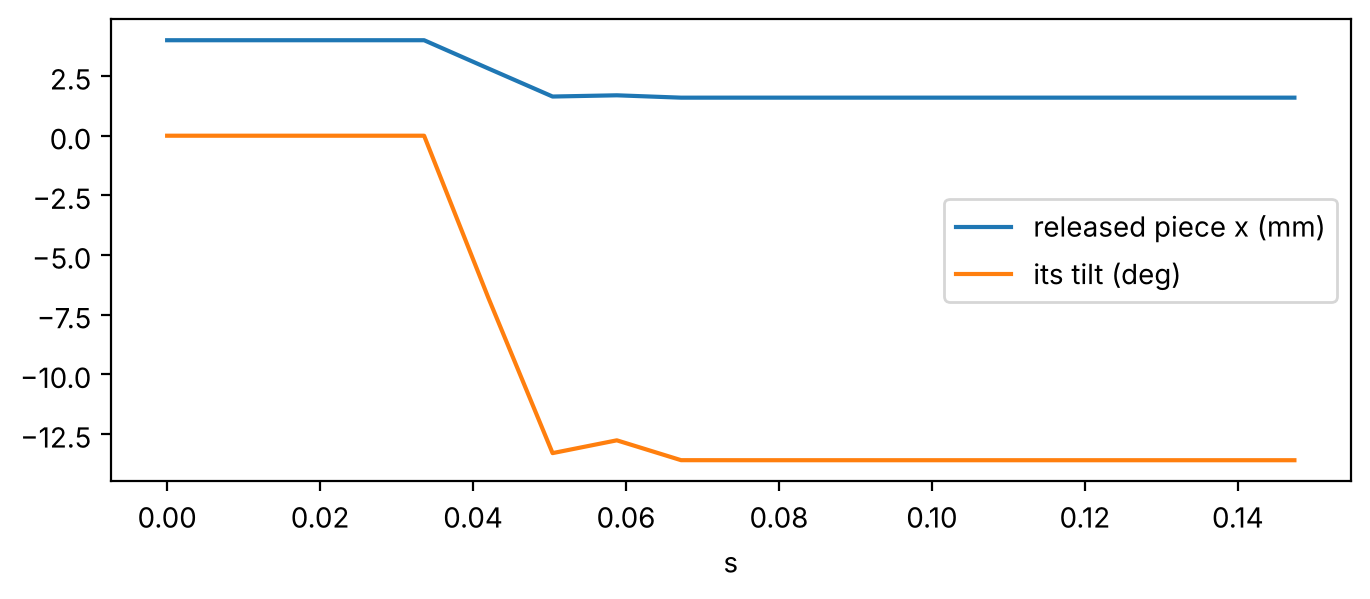

In [5]:
from stackpieces.sim2d import Section2D
from stackpieces.surface import section
sim = Section2D(g, section(g, "layered"))
r = sim.simulate(4.0, d=1.0, mu=0.3, record=True)
print(r["code"], f"final offset {r['dx']:.2f} mm, tilt {r['tilt']:.1f} deg, {len(r['frames'])} frames")
fr = np.array(r["frames"]); plt.figure(figsize=(8, 3)); plt.plot(fr[:, 0], fr[:, 4], label="released piece x (mm)")
plt.plot(fr[:, 0], np.degrees(fr[:, 6]), label="its tilt (deg)"); plt.xlabel("s"); plt.legend(); plt.show()